In [1]:
import os, warnings
from pathlib import Path
while not Path("pyproject.toml").exists() and Path.cwd() != Path.cwd().parent:
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve (the notebook sits in studies/<name>/notebooks)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.studies.italy_productivity.analysis.data import *
from cifresignificative.core.viz.style import *
apply_style()
panel = load_panel()


# 08 - Productivity by sector
Real gross value added per hour worked (Eurostat national accounts, chain-linked 2020 euro), nine NACE sections: real estate excluded because of imputed rents; public administration, education and health (O-Q) included, although their output is largely measured from inputs (a variant without them follows the shift-share). Only growth is compared across countries: euro levels would need PPPs.

Last year: 2025 | Italy: 101.5 | median of others: 126.8 | DEU/FRA/ESP: {'DEU': 114.1, 'FRA': 109.7, 'ESP': 115.3}


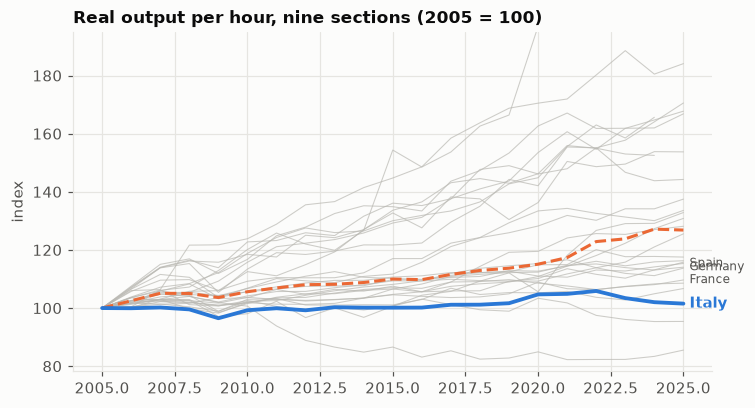

In [2]:
sectors = load_sectors()
agg = aggregate_productivity(sectors)
cover = agg[[c for c in agg if c in EU27_ISO3]].notna().sum(axis=1)
agg = agg.loc[:cover[cover >= 20].index.max()]  # stop at the last year with broad country coverage
idx = agg / agg.loc[2005] * 100
fig, ax = plt.subplots(figsize=(7.5, 4))
for c in EU27_ISO3:
    if c != ITALY and c in idx: ax.plot(idx.index, idx[c], color=PEER_C, lw=0.7, alpha=0.7)
for c, lab in [("DEU", "Germany"), ("FRA", "France"), ("ESP", "Spain")]:
    ax.annotate(lab, (idx[c].dropna().index.max(), idx[c].dropna().iloc[-1]), xytext=(4, 0), textcoords="offset points", fontsize=8, color=INK2, va="center")
med = idx[[c for c in idx if c in EU27_ISO3 and c != ITALY]].median(axis=1)
ax.plot(med.index, med, color=EU_C, lw=2, ls="--"); ax.plot(idx.index, idx[ITALY], color=ITALY_C, lw=2.5)
ax.annotate("Italy", (idx[ITALY].dropna().index.max(), idx[ITALY].dropna().iloc[-1]), xytext=(4, 0), textcoords="offset points", color=ITALY_C, fontweight="bold", va="center")
lo, hi = np.nanpercentile(idx.values, [1, 99]); ax.set_ylim(lo - 5, hi + 5)
ax.set_title("Real output per hour, nine sections (2005 = 100)"); ax.set_ylabel("index"); save(fig, "08_productivity_index")
y1 = int(agg[ITALY].dropna().index.max()); print("Last year:", y1, "| Italy:", round(idx.loc[y1, ITALY], 1), "| median of others:", round(med.loc[y1], 1), "| DEU/FRA/ESP:", idx.loc[y1, ["DEU", "FRA", "ESP"]].round(1).to_dict())

members in the sample: 25 | left out: ['BGR', 'LVA']


,Italy,median of others,Germany
"Public admin, education, health",-0.80,-0.03,0.14
Professional & admin services,-0.59,0.80,-0.06
Construction,-0.33,0.07,-1.43
"Arts, other services",-0.11,0.09,-0.00
Agriculture,0.15,2.40,2.46
"Industry (mining, manufacturing, utilities)",0.59,1.49,1.22
Finance & insurance,0.65,1.29,0.65
"Trade, transport, hospitality",0.69,1.12,1.14
Information & communication,0.90,1.82,2.91


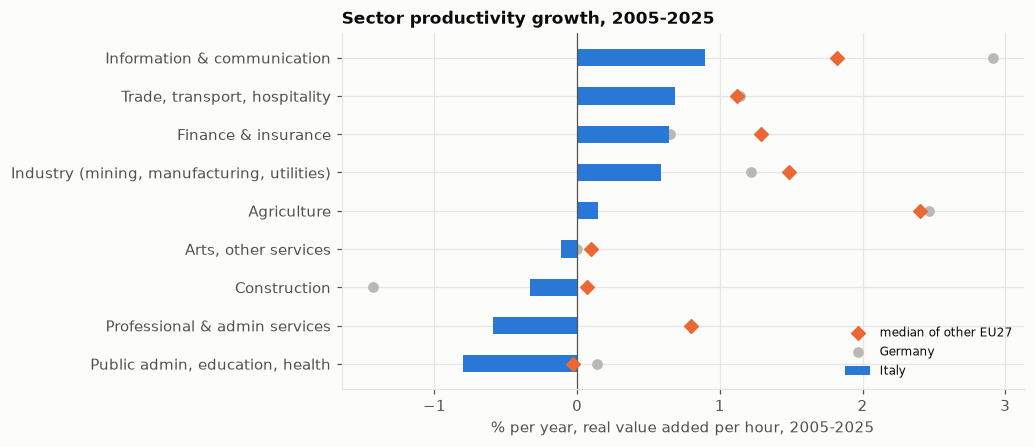

In [3]:
# Sector productivity growth, 2005-2025 (average annual log growth), Italy vs the median of the other members; same sample as the shift-share below (members with all nine sections in both years)
A, B = 2005, 2025  # 2025 is a first estimate (Eurostat release of 21 Oct 2026): Bulgaria and Latvia have no 2025 value added
SAMPLE = [c for c in EU27_ISO3 if c in sectors.iso3.unique() and shift_share(sectors, c, A, B).notna().all()]; print("members in the sample:", len(SAMPLE), "| left out:", sorted(set(EU27_ISO3) - set(SAMPLE)))
def sector_growth(a, b):
    p = sectors.pivot_table(index="iso3", columns=["nace_r2", "year"], values="prod")
    return pd.DataFrame({n: np.log(p[(n, b)] / p[(n, a)]) / (b - a) * 100 for n in NINE_SECTIONS})
g = sector_growth(A, B).loc[SAMPLE]
tab = pd.DataFrame({"Italy": g.loc[ITALY], "median of others": g.drop(ITALY).median(), "Germany": g.loc["DEU"]}).rename(index=SECTOR_LABELS).sort_values("Italy")
fig, ax = plt.subplots(figsize=(8, 4.2)); yy = np.arange(len(tab))
ax.scatter(tab["median of others"], yy, color=EU_C, s=40, zorder=3, label="median of other EU27", marker="D")
ax.scatter(tab["Germany"], yy, color=PEER_C, s=36, zorder=2, label="Germany")
ax.barh(yy, tab["Italy"], color=ITALY_C, height=0.45, zorder=2, label="Italy")
ax.set_yticks(yy, tab.index); ax.axvline(0, color=INK2, lw=0.8); ax.set_xlabel("% per year, real value added per hour, 2005-2025")
ax.set_title("Sector productivity growth, 2005-2025"); ax.legend(fontsize=8, loc="lower right"); save(fig, "08_sector_growth"); display(tab.round(2))

median total change (the parts do not add up to it): 26.8 | countries: 24


,within-sector productivity,reallocation of hours,interaction
ITA,2.5,0.1,-1.2
DEU,14.6,0.4,-1.0
FRA,9.3,1.3,-0.9
ESP,16.4,-0.2,-0.9
PRT,14.0,7.6,-5.3
GRC,-13.1,0.5,-1.9
EU median (excl. IT),21.9,3.4,-1.0


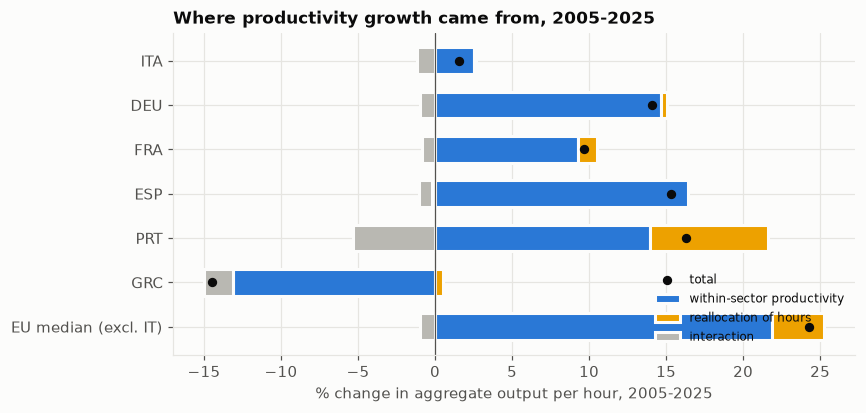

In [4]:
# Shift-share: within-sector productivity vs reallocation of hours across sectors (percent change in aggregate productivity)
countries = ["ITA", "DEU", "FRA", "ESP", "PRT", "GRC"]
rows = {c: shift_share(sectors, c, A, B) for c in countries}
oth = pd.DataFrame({c: shift_share(sectors, c, A, B) for c in SAMPLE if c != ITALY}).T; print('median total change (the parts do not add up to it):', round(oth.sum(axis=1).median(), 1), '| countries:', len(oth)); oth = oth.median()
dec = pd.DataFrame(rows).T; dec.loc["EU median (excl. IT)"] = oth
fig, ax = plt.subplots(figsize=(8, 3.8)); cols = ["#2a78d6", "#eda100", "#b9b8b2"]
pos = np.zeros(len(dec)); neg = np.zeros(len(dec))
for part, col in zip(dec.columns, cols):
    v = dec[part].values; base = np.where(v >= 0, pos, neg)
    ax.barh(range(len(dec)), v, left=base, color=col, height=0.6, label=part, edgecolor=SURFACE, linewidth=2)
    pos += np.where(v >= 0, v, 0); neg += np.where(v < 0, v, 0)
ax.scatter(dec.sum(axis=1), range(len(dec)), color=INK, s=26, zorder=5, label="total")
ax.set_yticks(range(len(dec)), dec.index); ax.invert_yaxis(); ax.axvline(0, color=INK2, lw=0.8)
ax.set_xlabel("% change in aggregate output per hour, 2005-2025"); ax.set_title("Where productivity growth came from, 2005-2025"); ax.legend(fontsize=8, loc="lower right"); save(fig, "08_shift_share")
display(dec.round(1))

In [5]:
# Variant: the eight market sections (without O-Q, public administration, education and health, whose output is largely measured from inputs); same 25 members
mk = sectors[sectors.nace_r2.isin(MARKET_SECTIONS)]
var = pd.DataFrame({c: shift_share(mk, c, A, B) for c in SAMPLE}).T; var["total"] = var.sum(axis=1)
print("without O-Q, Italy:", var.loc[ITALY].round(1).to_dict(), "| median of the others:", var.drop(ITALY).median().round(1).to_dict(), "| Italy's rank from the bottom (within):", int((var.iloc[:, 0] <= var.loc[ITALY].iloc[0]).sum()), "of", len(var))

without O-Q, Italy: {'within-sector productivity': 7.2, 'reallocation of hours': -0.2, 'interaction': -1.3, 'total': 5.8} | median of the others: {'within-sector productivity': 28.4, 'reallocation of hours': 4.3, 'interaction': -1.0, 'total': 33.3} | Italy's rank from the bottom (within): 3 of 25


In [6]:
# Structure: share of hours by sector, 2005 vs latest year with data (Italy vs median of the others)
def hshare(y):
    h = sectors.pivot_table(index="iso3", columns=["nace_r2", "year"], values="hours_ths")
    t = pd.DataFrame({n: h[(n, y)] for n in NINE_SECTIONS}); return t.div(t.sum(axis=1), axis=0) * 100
a, b = hshare(A), hshare(B)
out = pd.DataFrame({"Italy 2005": a.loc[ITALY], "Italy 2025": b.loc[ITALY], "others 2005 (median)": a.drop(ITALY).median(), "others 2025 (median)": b.drop(ITALY).median()}).rename(index=SECTOR_LABELS)
display(out.round(1))

,Italy 2005,Italy 2025,others 2005 (median),others 2025 (median)
Agriculture,5.5,4.8,8.0,3.9
"Industry (mining, manufacturing, utilities)",20.6,17.0,18.8,14.7
Construction,7.7,7.7,8.0,7.8
"Trade, transport, hospitality",27.2,27.2,24.9,24.2
Information & communication,2.6,2.8,2.3,4.3
Finance & insurance,2.7,2.3,2.1,2.1
Professional & admin services,9.9,13.6,8.6,12.3
"Public admin, education, health",15.4,16.0,20.0,22.4
"Arts, other services",8.4,8.6,4.5,4.7


## Takeaways (Eurostat national accounts; nine sections excl. real estate, O-Q included; 2005-2025, 2025 a first estimate, data of 21 October 2026)
- **Aggregate output per hour barely moved:** index 2005 = 100 reaches 102 in 2025 for Italy against 127 for the median of the other members (Germany 114, France 110, Spain 115).
- **The gap is within sectors, not between them.** Over 2005-2025 within-sector productivity added +2.5% for Italy vs +21.9% for the median of the other 24 members of the sample (Germany +14.6, France +9.3, Spain +16.4; Italy is 3rd lowest of 25); the reallocation of hours across the nine broad sections was +0.1 for Italy vs +3.4 median, the interaction -1.2 vs -1.0, and the total change +1.5% vs +26.8% (median of the totals: the medians of the parts do not add up). A shift of hours between sections is therefore not what explains the gap. Without public administration, education and health (O-Q, output largely measured from inputs) the within-sector terms are +7.2% vs +28.4% (reallocation -0.2 vs +4.3, total +5.8% vs +33.3%), Italy still 3rd lowest of 25: the levels move, the conclusion does not. The sample is the 25 members with all nine sections in 2005 and 2025 (Bulgaria and Latvia have no 2025 value added yet). For 2005-2019 the same 25 members give +2.8 vs +14.3 within sectors, -0.5 vs +2.1 reallocation (all 27 members: +16.2 and +2.4). This view cannot see misallocation across *firms within* a section, which is where the literature (Hsieh-Klenow; Gopinath et al.) places it: that needs firm-level data.
- **Italy trails the median in all nine sections over 2005-2025** (seven of nine over 2005-2019). Annual growth in output per hour: agriculture +0.15% (median +2.4%), information & communication +0.9% (+1.8%), industry +0.6% (+1.5%), finance +0.65% (+1.3%), trade, transport & hospitality +0.7% (+1.1%), professional & administrative services -0.6% (+0.8%), construction -0.3% (+0.1%), public administration, education and health -0.8% (0.0%), arts and other services -0.1% (+0.1%). **Construction is period-dependent:** -1.4% a year against +0.4% in 2005-2019, but +2.3% a year against -1.3% in 2019-2025, a period that contains the building-bonus years (a coincidence in time, not tested; construction value added also carries measurement questions).
- Structure: industry fell from 20.6% to 17.0% of hours (2005-2025) while professional & administrative services rose from 9.9% to 13.6%, a sector where measured productivity fell. Deflators in services are harder to measure, so sector rankings should be treated with care.